Raw dataset shape: (541909, 8)
Cleaned dataset shape: (397884, 9)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


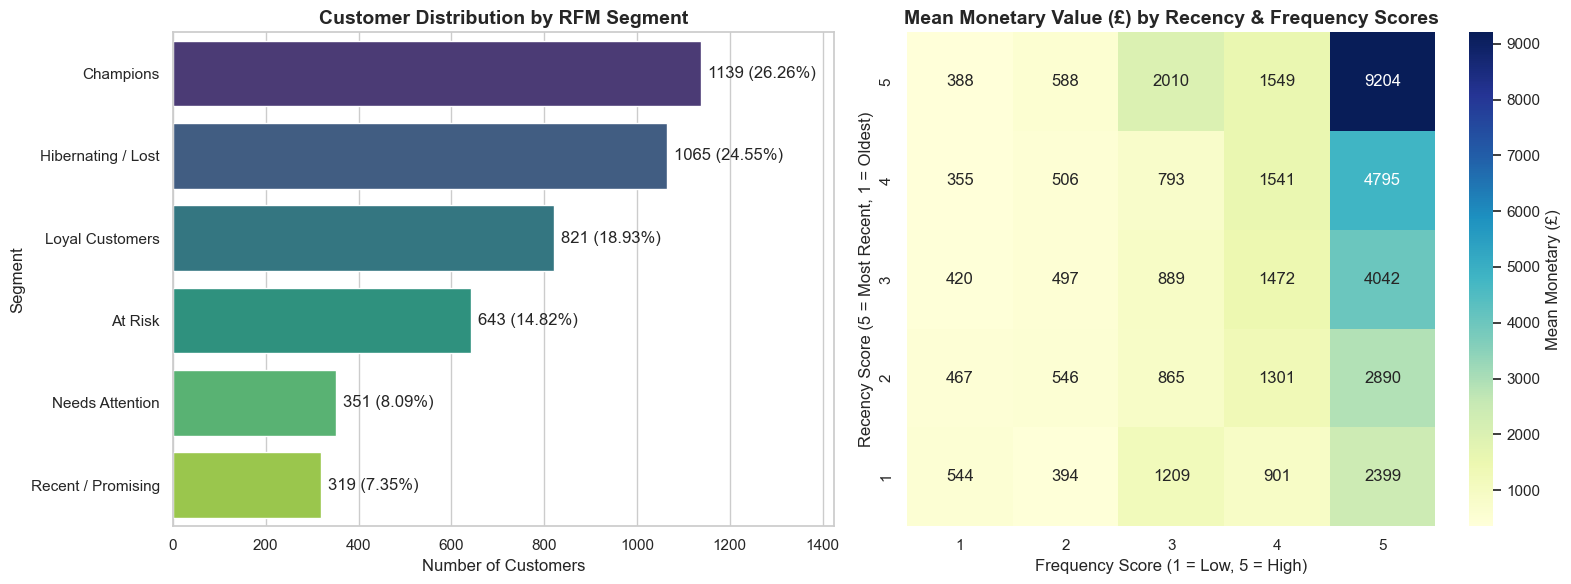

In [1]:

# 1. Import Libraries & Load Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load the Excel dataset
xls = pd.ExcelFile('Online Retail.xlsx')
df = pd.read_excel(xls, sheet_name='Online Retail')

print(f"Raw dataset shape: {df.shape}")
df.head()

# %%
# 2. Data Cleaning & Feature Engineering
# Drop rows without CustomerID
df_clean = df.dropna(subset=['CustomerID']).copy()

# Remove cancelled transactions (InvoiceNo starting with 'C')
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C')]

# Keep positive quantities and unit prices
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# Format CustomerID and compute line-item revenue
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']

print(f"Cleaned dataset shape: {df_clean.shape}")
print(f"Date range: {df_clean['InvoiceDate'].min()} to {df_clean['InvoiceDate'].max()}")

# %%
# 3. Compute RFM Metrics
# Reference date set to 1 day after the latest transaction in the dataset
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency (days)
    'InvoiceNo': 'nunique',                                   # Frequency (unique orders)
    'TotalPrice': 'sum'                                       # Monetary (total spend)
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']
rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2)

# %%
# 4. Assign RFM Quintile Scores (1 to 5)
# Lower Recency (fewer days since last purchase) gets a higher score (5)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)

# Higher Frequency and Monetary get higher scores (5); rank(method='first') breaks ties cleanly
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# Combined RFM Score string
rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm.head()

# %%
# 5. Customer Segmentation Logic
def assign_segment(row):
    r, f = row['R_Score'], row['F_Score']
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'Recent / Promising'
    elif r == 3 and f <= 2:
        return 'Needs Attention'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    else:
        return 'Hibernating / Lost'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

# Aggregate segment performance
segment_summary = rfm.groupby('Segment').agg(
    Customer_Count=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).sort_values(by='Customer_Count', ascending=False).round(2)

segment_summary['Customer_Share_%'] = (segment_summary['Customer_Count'] / len(rfm) * 100).round(2)
segment_summary['Revenue_Share_%'] = (segment_summary['Total_Revenue'] / rfm['Monetary'].sum() * 100).round(2)

segment_summary

# %%
# 6. Bonus: Visualizations (Bar Chart & RFM Heatmap)
plot_df = segment_summary.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar Chart: Customer Count per Segment
sns.barplot(
    data=plot_df,
    x='Customer_Count',
    y='Segment',
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Customer Distribution by RFM Segment', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Customers')
axes[0].set_ylabel('Segment')
axes[0].set_xlim(0, plot_df['Customer_Count'].max() * 1.25)

for i, row in plot_df.iterrows():
    axes[0].text(
        row['Customer_Count'] + 15, i,
        f"{int(row['Customer_Count'])} ({row['Customer_Share_%']}%)",
        va='center'
    )

# Heatmap: Average Monetary Value across R_Score and F_Score
rfm_pivot = rfm.pivot_table(index='R_Score', columns='F_Score', values='Monetary', aggfunc='mean')
rfm_pivot = rfm_pivot.sort_index(ascending=False)

sns.heatmap(
    rfm_pivot,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    ax=axes[1],
    cbar_kws={'label': 'Mean Monetary (£)'}
)
axes[1].set_title('Mean Monetary Value (£) by Recency & Frequency Scores', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Frequency Score (1 = Low, 5 = High)')
axes[1].set_ylabel('Recency Score (5 = Most Recent, 1 = Oldest)')

plt.tight_layout()
plt.show()